# Profitability Optimization — Global Superstore (2011–2014)

**Business problem:** The company has achieved strong revenue growth, but profitability is uneven across products,
markets, customers and discount levels. Management needs to find the major sources of profit leakage and decide
which combinations of pricing, products, customers, regions and shipping add to or reduce profitability.

**Key questions**
1. Is revenue growth translating into profit?
2. How much profit is being lost, and where?
3. At what discount level do sales stop being profitable?
4. Which products, markets and customers are driving the losses?
5. Is shipping a significant cost problem?
6. What would a discount policy change be worth?

**Contents:** 1. Data Understanding → 2. Data Cleaning → 3. EDA → 4. Profitability Analysis → 5. Recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

df_raw = pd.read_csv("superstore.csv")

# 1. Data Understanding

In [2]:
print("Rows, Columns:", df_raw.shape)
df_raw.head()

Rows, Columns: (51290, 27)


,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,Order.Priority,Product.ID,Product.Name,Profit,Quantity,Region,Row.ID,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.00,US,1,2011-01-07 00:00:00.000,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.33,3,West,36624,19,Consumer,2011-01-09 00:00:00.000,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.00,US,1,2011-01-21 00:00:00.000,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.29,2,West,37033,19,Consumer,2011-01-26 00:00:00.000,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.00,US,1,2011-08-05 00:00:00.000,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.84,3,West,31468,21,Consumer,2011-08-09 00:00:00.000,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.00,US,1,2011-08-05 00:00:00.000,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.26,2,West,31469,111,Consumer,2011-08-09 00:00:00.000,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.00,US,1,2011-09-29 00:00:00.000,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.11,1,West,32440,6,Consumer,2011-10-03 00:00:00.000,Standard Class,1.32,California,Paper,2011,North America,40


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  str    
 1   City            51290 non-null  str    
 2   Country         51290 non-null  str    
 3   Customer.ID     51290 non-null  str    
 4   Customer.Name   51290 non-null  str    
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  str    
 7   记录数             51290 non-null  int64  
 8   Order.Date      51290 non-null  str    
 9   Order.ID        51290 non-null  str    
 10  Order.Priority  51290 non-null  str    
 11  Product.ID      51290 non-null  str    
 12  Product.Name    51290 non-null  str    
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  str    
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-null  int64  
 1

In [4]:
pd.DataFrame({
    "nulls": df_raw.isna().sum(),
    "unique_values": df_raw.nunique(),
})

,nulls,unique_values
Category,0,3
City,0,3636
Country,0,147
Customer.ID,0,4873
Customer.Name,0,795
Discount,0,27
Market,0,7
记录数,0,1
Order.Date,0,1430
Order.ID,0,25035


In [5]:
print("Duplicate rows   :", df_raw.duplicated().sum())
print("Duplicate Row.ID :", df_raw["Row.ID"].duplicated().sum())
print("Customer IDs     :", df_raw["Customer.ID"].nunique(), "| Customer names:", df_raw["Customer.Name"].nunique())
print("Product IDs with >1 name:", (df_raw.groupby("Product.ID")["Product.Name"].nunique() > 1).sum())
print("Rows with Sales <= 0:", (df_raw["Sales"] <= 0).sum())
print("Discount values:", sorted(df_raw["Discount"].unique().tolist()))

Duplicate rows   : 0
Duplicate Row.ID : 0
Customer IDs     : 4873 | Customer names: 795
Product IDs with >1 name: 457
Rows with Sales <= 0: 1
Discount values: [0.0, 0.002, 0.07, 0.1, 0.15, 0.17, 0.2, 0.202, 0.25, 0.27, 0.3, 0.32, 0.35, 0.37, 0.4, 0.402, 0.45, 0.47, 0.5, 0.55, 0.57, 0.6, 0.602, 0.65, 0.7, 0.8, 0.85]


**Observations**

- 51,290 order lines across 27 columns, with no missing values and no duplicates.
- `记录数` ("record count") is always 1, so it adds nothing.
- `Customer.ID` has 4,873 values but only 795 customer names, which means the ID is specific to each market. A "customer" in this analysis is therefore one customer account in one market.
- 457 `Product.ID`s are shared by more than one product name, so products are identified by ID + name.
- Discounts include odd values (0.002, 0.202, 0.402, 0.602) next to the standard 0, 0.2, 0.4 and 0.6 tiers.
- One line has zero sales.

# 2. Data Cleaning

In [6]:
df = df_raw.copy()

# 1. Drop the constant column
df = df.drop(columns=["记录数"])

# 2. Clean column names: "Order.Date" -> "order_date"
df.columns = df.columns.str.replace(".", "_").str.lower()

# 3. Convert dates
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

# 4. Validate business rules
print("Ship date before order date:", (df["ship_date"] < df["order_date"]).sum())
print("Discount outside 0-1       :", (~df["discount"].between(0, 1)).sum())

# 5. Remove the zero-sales line (margin cannot be calculated)
df = df[df["sales"] > 0]

# 6. Fix discount precision errors (0.202 -> 0.20)
print("Discount values fixed:", (df["discount"] != df["discount"].round(2)).sum())
df["discount"] = df["discount"].round(2)

print("Clean shape:", df.shape)

Ship date before order date: 0
Discount outside 0-1       : 0
Discount values fixed: 629
Clean shape: (51289, 26)


### Feature engineering

In [7]:
df["product"] = df["product_id"] + " | " + df["product_name"]      # unique product key
df["month"] = df["order_date"].dt.month
df["ship_days"] = (df["ship_date"] - df["order_date"]).dt.days

df["profit_margin"] = df["profit"] / df["sales"]
df["is_loss"] = df["profit"] < 0
df["list_price_sales"] = df["sales"] / (1 - df["discount"])           # revenue before discount
df["discount_amount"] = df["list_price_sales"] - df["sales"]
df["shipping_pct"] = df["shipping_cost"] / df["sales"]

df["discount_band"] = pd.cut(
    df["discount"],
    bins=[-0.01, 0, 0.10, 0.20, 0.30, 0.40, 0.50, 1],
    labels=["0%", "1-10%", "11-20%", "21-30%", "31-40%", "41-50%", ">50%"],
)
df.head()

,category,city,country,customer_id,customer_name,discount,market,order_date,order_id,order_priority,product_id,product_name,profit,quantity,region,...,shipping_cost,state,sub_category,year,market2,weeknum,product,month,ship_days,profit_margin,is_loss,list_price_sales,discount_amount,shipping_pct,discount_band
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.00,US,2011-01-07,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.33,3,West,...,4.37,California,Paper,2011,North America,2,OFF-PA-10002005 | Xerox 225,1,2,0.49,False,19.00,0.00,0.23,0%
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.00,US,2011-01-21,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.29,2,West,...,0.94,California,Paper,2011,North America,4,OFF-PA-10002893 | Wirebound Service Call Books...,1,5,0.49,False,19.00,0.00,0.05,0%
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.00,US,2011-08-05,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.84,3,West,...,1.81,California,Paper,2011,North America,32,"OFF-PA-10000659 | Adams Phone Message Book, Pr...",8,4,0.47,False,21.00,0.00,0.09,0%
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.00,US,2011-08-05,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.26,2,West,...,4.59,California,Paper,2011,North America,32,OFF-PA-10001144 | Xerox 1913,8,4,0.48,False,111.00,0.00,0.04,0%
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.00,US,2011-09-29,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.11,1,West,...,1.32,California,Paper,2011,North America,40,OFF-PA-10002105 | Xerox 223,9,4,0.52,False,6.00,0.00,0.22,0%


In [8]:
# Reusable summary: sales, profit, margin and average discount for any grouping
def summary(data, by):
    s = data.groupby(by, observed=True).agg(
        sales=("sales", "sum"),
        profit=("profit", "sum"),
        avg_discount=("discount", "mean"),
        lines=("sales", "size"),
    )
    s["margin"] = s["profit"] / s["sales"]
    return s

# 3. Exploratory Data Analysis

### 3.1 Headline KPIs

In [9]:
total_sales, total_profit = df["sales"].sum(), df["profit"].sum()
kpi = pd.Series({
    "Total sales": f"${total_sales:,.0f}",
    "Total profit": f"${total_profit:,.0f}",
    "Profit margin": f"{total_profit / total_sales:.1%}",
    "Orders": f"{df['order_id'].nunique():,}",
    "Customer accounts": f"{df['customer_id'].nunique():,}",
    "Products": f"{df['product'].nunique():,}",
    "Countries": df["country"].nunique(),
    "Loss-making lines": f"{df['is_loss'].mean():.1%}",
})
kpi.to_frame("value")

,value
Total sales,"$12,642,905"
Total profit,"$1,467,458"
Profit margin,11.6%
Orders,"25,035"
Customer accounts,"4,873"
Products,"10,768"
Countries,147
Loss-making lines,24.5%


### 3.2 Distributions

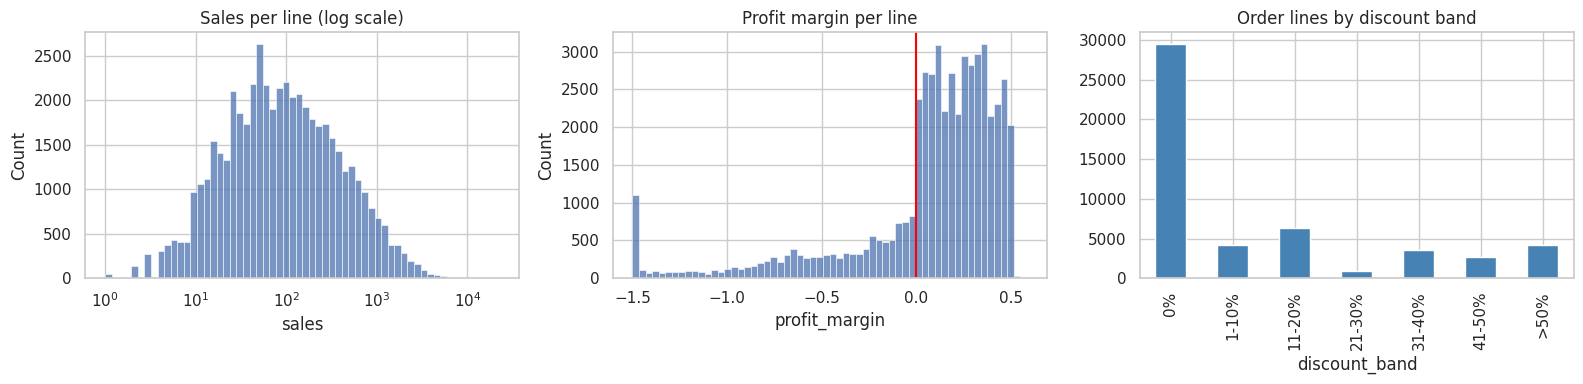

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["sales"], bins=60, log_scale=True, ax=ax[0]).set_title("Sales per line (log scale)")
sns.histplot(df["profit_margin"].clip(-1.5, 0.6), bins=60, ax=ax[1]).set_title("Profit margin per line")
ax[1].axvline(0, color="red")
df["discount_band"].value_counts(sort=False).plot.bar(ax=ax[2], color="steelblue", title="Order lines by discount band")
plt.tight_layout(); plt.show()

- Sales per line are heavily right-skewed. Most lines are small, but a long tail of large orders exists.
- Margin has a clear negative tail, with 24% of lines losing money.
- 57% of lines carry no discount, but a significant group sits above 30%.

### 3.3 Correlation between numeric variables

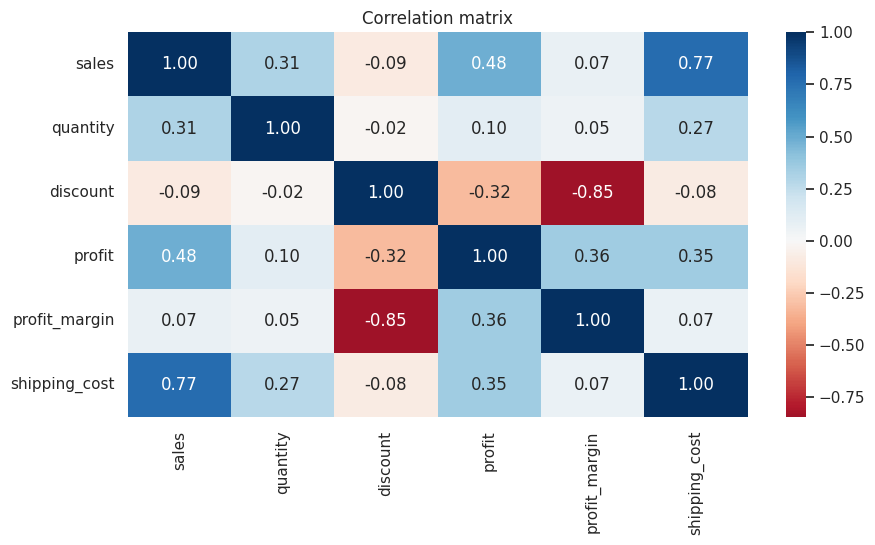

In [11]:
num = df[["sales", "quantity", "discount", "profit", "profit_margin", "shipping_cost"]]
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu", center=0)
plt.title("Correlation matrix"); plt.show()

**Discount has a –0.85 correlation with profit margin, the strongest relationship in the data.** Discount has almost
no relationship with quantity. That is the first sign that discounts reduce margin without increasing volume.

### 3.4 Sales mix by category, segment, market and ship mode

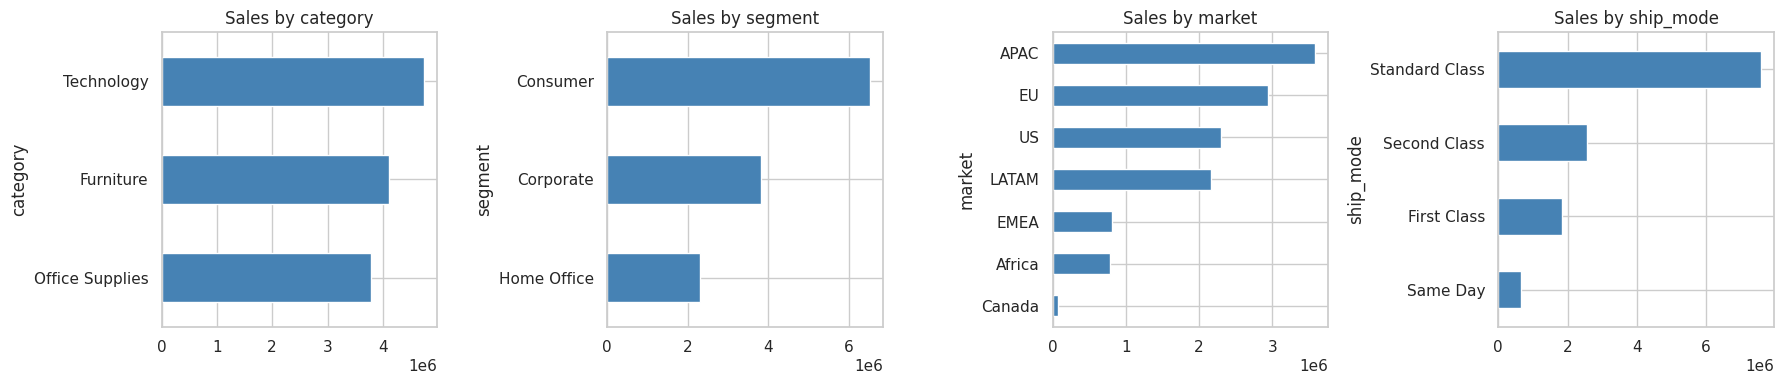

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, ["category", "segment", "market", "ship_mode"]):
    df.groupby(col)["sales"].sum().sort_values().plot.barh(ax=a, color="steelblue", title=f"Sales by {col}")
plt.tight_layout(); plt.show()

### 3.5 Trend over time

,sales,profit,avg_discount,lines,margin,sales_growth
year,,,,,,
2011,2259511,"248,940.81",0.15,8998,0.11,NaN
2012,2677493,"307,415.28",0.14,10962,0.11,0.18
2013,3405860,"406,935.23",0.14,13799,0.12,0.27
2014,4300041,"504,167.08",0.14,17530,0.12,0.26


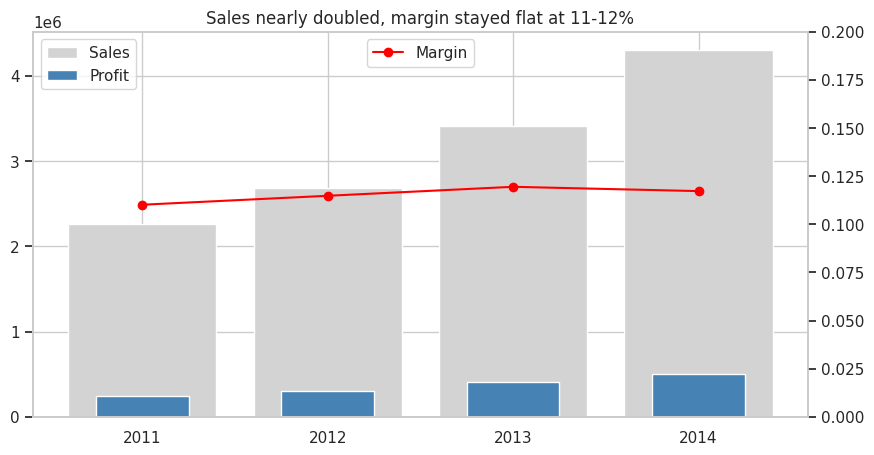

In [13]:
yearly = summary(df, "year")
yearly["sales_growth"] = yearly["sales"].pct_change()
display(yearly)

fig, ax = plt.subplots()
ax.bar(yearly.index.astype(str), yearly["sales"], color="lightgray", label="Sales")
ax.bar(yearly.index.astype(str), yearly["profit"], color="steelblue", width=0.5, label="Profit")
ax2 = ax.twinx()
ax2.plot(yearly.index.astype(str), yearly["margin"], color="red", marker="o", label="Margin")
ax2.set_ylim(0, 0.2); ax2.grid(False)
ax.legend(loc="upper left"); ax2.legend(loc="upper center")
plt.title("Sales nearly doubled, margin stayed flat at 11-12%"); plt.show()

Sales grew about 90% from 2011 to 2014, while margin stayed at 11–12%. **Growth comes from volume, not from better
economics.** Each extra dollar of sales still earns about 12 cents.

### 3.6 Seasonality

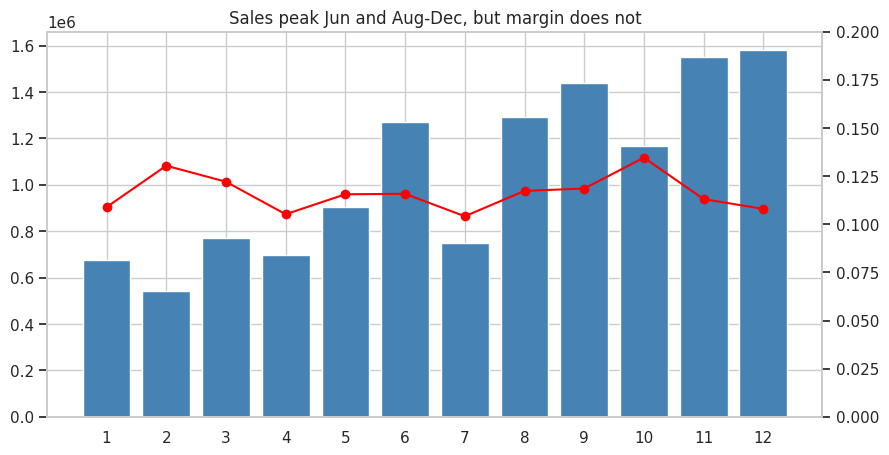

June + Aug-Dec share of sales: 66%


In [14]:
monthly = summary(df, "month")
monthly["share_of_sales"] = monthly["sales"] / monthly["sales"].sum()

fig, ax = plt.subplots()
ax.bar(monthly.index, monthly["sales"], color="steelblue")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["margin"], color="red", marker="o")
ax2.set_ylim(0, 0.2); ax2.grid(False)
ax.set_xticks(range(1, 13))
plt.title("Sales peak Jun and Aug-Dec, but margin does not"); plt.show()

peak = monthly.loc[[6, 8, 9, 10, 11, 12], "share_of_sales"].sum()
print(f"June + Aug-Dec share of sales: {peak:.0%}")

Peak months carry about two-thirds of sales, but margin does not improve. It dips slightly in Nov–Dec, which suggests
heavier year-end discounting.

# 4. Profitability Analysis

### 4.1 How much profit is being lost?

Profit earned by profitable lines : $2,388,103
Profit lost by loss-making lines  : $-920,645  (39% of profit earned)
Net profit                        : $1,467,458


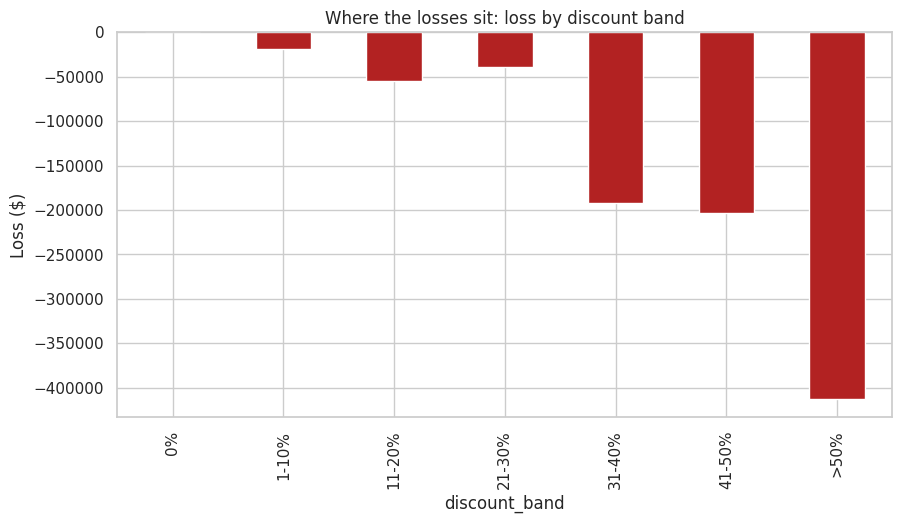

Share of losses from lines discounted above 30%: 88%


In [15]:
profit_earned = df.loc[~df["is_loss"], "profit"].sum()
profit_lost = df.loc[df["is_loss"], "profit"].sum()
print(f"Profit earned by profitable lines : ${profit_earned:,.0f}")
print(f"Profit lost by loss-making lines  : ${profit_lost:,.0f}  ({-profit_lost / profit_earned:.0%} of profit earned)")
print(f"Net profit                        : ${total_profit:,.0f}")

losses = df[df["is_loss"]].groupby("discount_band", observed=True)["profit"].sum()
losses.plot.bar(color="firebrick", title="Where the losses sit: loss by discount band")
plt.ylabel("Loss ($)"); plt.show()
print(f"Share of losses from lines discounted above 30%: {losses[['31-40%','41-50%','>50%']].sum() / losses.sum():.0%}")

**Loss-making lines wipe out $921K, which is 39% of the profit earned.** 88% of those losses come from lines
discounted above 30%. The leakage is concentrated, which makes it fixable.

### 4.2 Discount level vs profitability

,sales,profit,avg_discount,lines,margin,loss_rate,avg_qty
discount_band,,,,,,,
0%,7254129,"1,828,671.85",0.00,29470,0.25,0.00,3.41
1-10%,1701238,"280,212.68",0.10,4218,0.16,0.21,3.78
11-20%,1773509,"172,659.57",0.19,6315,0.10,0.24,3.73
21-30%,366327,"-20,560.34",0.28,926,-0.06,0.62,3.83
31-40%,735104,"-177,545.90",0.40,3504,-0.24,0.80,3.64
41-50%,440974,"-203,398.92",0.49,2685,-0.46,0.96,3.81
>50%,371624,"-412,580.55",0.66,4171,-1.11,1.00,2.85


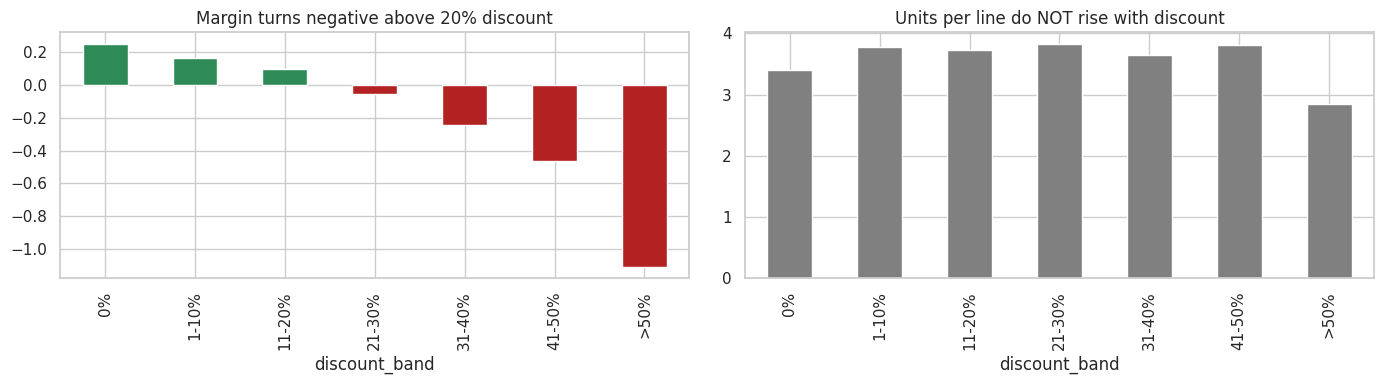

In [16]:
bands = summary(df, "discount_band")
bands["loss_rate"] = df.groupby("discount_band", observed=True)["is_loss"].mean()
bands["avg_qty"] = df.groupby("discount_band", observed=True)["quantity"].mean()
display(bands)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
bands["margin"].plot.bar(ax=ax[0], color=np.where(bands["margin"] > 0, "seagreen", "firebrick"),
                         title="Margin turns negative above 20% discount")
bands["avg_qty"].plot.bar(ax=ax[1], color="gray", title="Units per line do NOT rise with discount")
plt.tight_layout(); plt.show()

- Margin falls from 25% at full price to –6% at a 21–30% discount and –111% above 50%.
- **Deeper discounts do not sell more units.** Units per line stay flat at about 3.4–3.8, so the discount is simply given away.

### 4.3 The break-even discount for each sub-category

If a product earns margin *m* at full price, it loses money once the discount exceeds *m*. For example, a product
with a 25% full-price margin breaks even at a 25% discount. **The maximum safe discount therefore equals the
full-price margin**, which can be measured from the 0%-discount lines.

,sales,margin,avg_discount,breakeven_discount,sales_above_breakeven
sub_category,,,,,
Tables,757034,-0.08,0.29,0.23,0.44
Chairs,1501682,0.09,0.16,0.24,0.19
Machines,779071,0.08,0.17,0.26,0.18
Furnishings,385609,0.12,0.15,0.25,0.17
Fasteners,83254,0.14,0.14,0.26,0.15
Envelopes,170926,0.17,0.13,0.29,0.14
Bookcases,1466559,0.11,0.15,0.24,0.14
Binders,461952,0.16,0.18,0.32,0.13
Supplies,243090,0.09,0.13,0.21,0.12


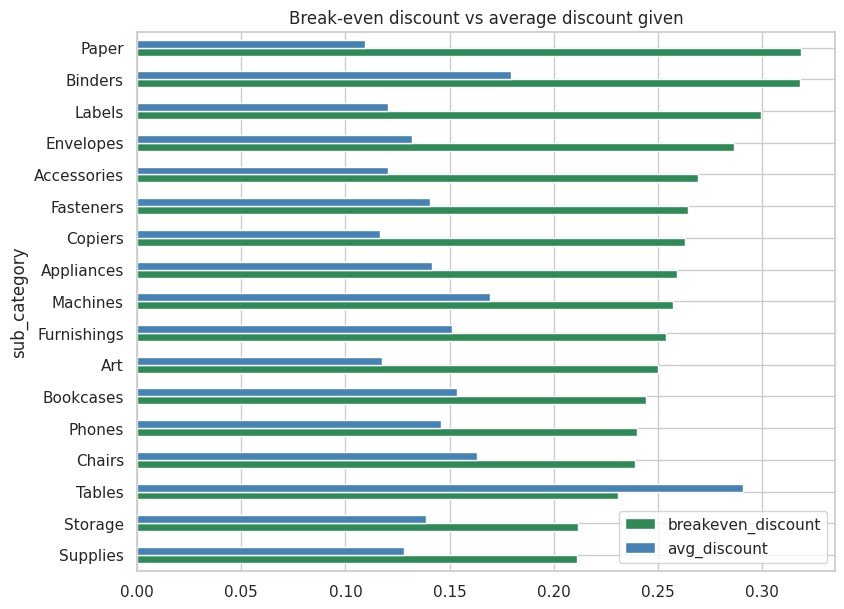

In [17]:
breakeven = (df[df["discount"] == 0].groupby("sub_category")
             .apply(lambda g: g["profit"].sum() / g["sales"].sum()))
df["breakeven_discount"] = df["sub_category"].map(breakeven)
df["above_breakeven"] = df["discount"] > df["breakeven_discount"]

be = summary(df, "sub_category")
be["breakeven_discount"] = breakeven
be["sales_above_breakeven"] = (df[df["above_breakeven"]].groupby("sub_category")["sales"].sum() / be["sales"])
be = be.sort_values("sales_above_breakeven", ascending=False)
display(be[["sales", "margin", "avg_discount", "breakeven_discount", "sales_above_breakeven"]])

be[["breakeven_discount", "avg_discount"]].sort_values("breakeven_discount").plot.barh(
    figsize=(9, 7), color=["seagreen", "steelblue"], title="Break-even discount vs average discount given")
plt.show()

In [18]:
impact = df.groupby("above_breakeven").agg(lines=("sales", "size"), loss_rate=("is_loss", "mean"), profit=("profit", "sum"))
impact["share_of_lines"] = impact["lines"] / impact["lines"].sum()
impact.index = ["Within break-even", "Above break-even"]
impact

,lines,loss_rate,profit,share_of_lines
Within break-even,40086,0.06,"2,280,956.32",0.78
Above break-even,11203,0.90,"-813,497.92",0.22


**22% of order lines are discounted beyond their break-even point. 90% of them lose money, together costing $813K.**
Tables stands out, with 44% of its sales priced below break-even.

### 4.4 Category and sub-category profitability

,sales,profit,avg_discount,lines,margin
category,,,,,
Furniture,4110884,"285,204.72",0.17,9876,0.07
Office Supplies,3787330,"518,474.94",0.14,31272,0.14
Technology,4744691,"663,778.73",0.14,10141,0.14


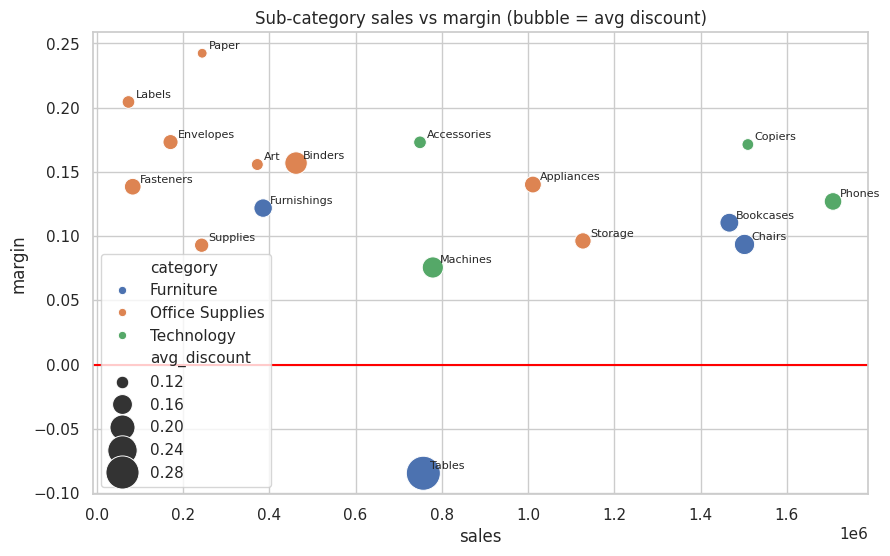

In [19]:
display(summary(df, "category"))

sub = summary(df, ["category", "sub_category"]).reset_index()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sub, x="sales", y="margin", hue="category", size="avg_discount", sizes=(50, 600))
for _, r in sub.iterrows():
    plt.annotate(r["sub_category"], (r["sales"], r["margin"]), fontsize=8, xytext=(5, 3), textcoords="offset points")
plt.axhline(0, color="red")
plt.title("Sub-category sales vs margin (bubble = avg discount)"); plt.show()

In [20]:
tables = df[df["sub_category"] == "Tables"]
print(f"Tables full-price margin: {breakeven['Tables']:.1%}  |  actual margin: {tables['profit'].sum() / tables['sales'].sum():.1%}")
summary(tables, "market").sort_values("profit")

Tables full-price margin: 23.1%  |  actual margin: -8.5%


,sales,profit,avg_discount,lines,margin
market,,,,,
EU,105380,"-20,998.42",0.37,91,-0.20
APAC,225096,"-20,128.75",0.33,189,-0.09
US,206968,"-17,725.48",0.26,319,-0.09
LATAM,144878,"-12,305.85",0.33,178,-0.08
Canada,850,300.18,0.00,2,0.35
EMEA,39331,"2,764.25",0.16,45,0.07
Africa,34531,"4,010.68",0.13,37,0.12


- Furniture has almost the same sales as Technology but half its margin (6.9% vs 14.0%).
- **Tables is the only loss-making sub-category** (–$64K, –8.5% margin).
- Tables earns 23% at full price, so its problem is **discounting, not product cost**. It loses money in APAC, EU, US and LATAM, which points to a product-level promotion policy rather than a local issue.

### 4.5 Geography: markets, regions, countries

,sales,profit,avg_discount,lines,margin
region,,,,,
Southeast Asia,884438,"17,852.33",0.27,3129,0.02
EMEA,806184,"43,897.97",0.20,5029,0.05
South,1600960,"140,355.77",0.15,6645,0.09
Caribbean,324281,"34,571.32",0.14,1690,0.11
Oceania,1100207,"120,089.11",0.15,3487,0.11
Central,2822399,"311,405.09",0.14,11116,0.11
Africa,783776,"88,871.63",0.16,4587,0.11
East,678834,"91,522.78",0.15,2848,0.13
West,725514,"108,418.45",0.11,3203,0.15


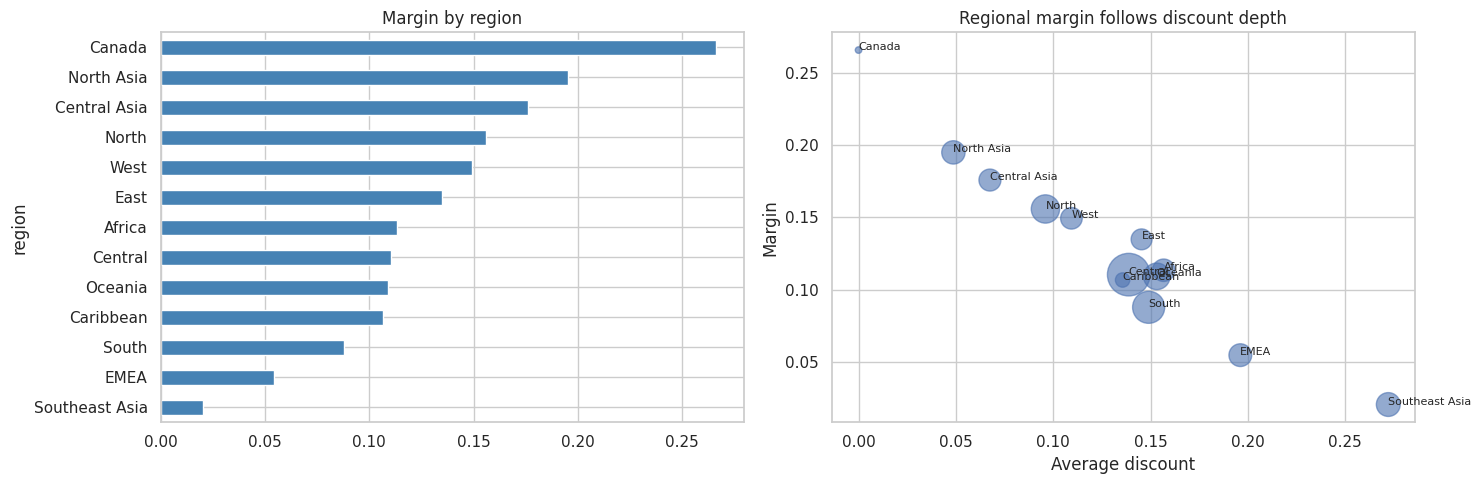

In [21]:
region = summary(df, "region").sort_values("margin")
display(region)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
region["margin"].plot.barh(ax=ax[0], color="steelblue", title="Margin by region")
ax[1].scatter(region["avg_discount"], region["margin"], s=region["sales"] / 3000, alpha=0.6)
for name, r in region.iterrows():
    ax[1].annotate(name, (r["avg_discount"], r["margin"]), fontsize=8)
ax[1].set_xlabel("Average discount"); ax[1].set_ylabel("Margin")
ax[1].set_title("Regional margin follows discount depth")
plt.tight_layout(); plt.show()

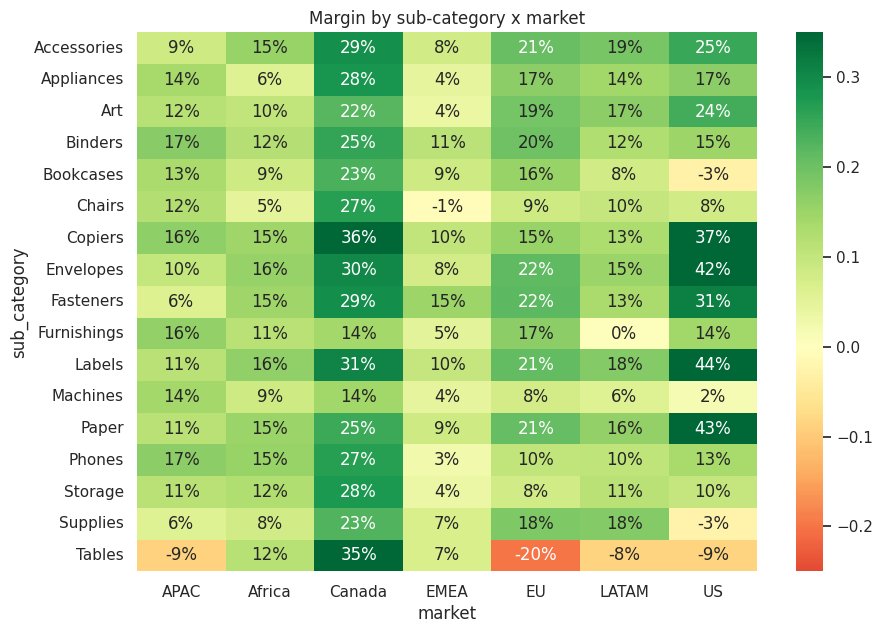

In [22]:
pivot = df.pivot_table(index="sub_category", columns="market", values=["profit", "sales"], aggfunc="sum")
margin_matrix = pivot["profit"] / pivot["sales"]
plt.figure(figsize=(10, 7))
sns.heatmap(margin_matrix, annot=True, fmt=".0%", cmap="RdYlGn", center=0, vmin=-0.25, vmax=0.35)
plt.title("Margin by sub-category x market"); plt.show()

In [23]:
country = summary(df, "country")
country["discounts_used"] = df.groupby("country")["discount"].apply(lambda s: sorted(s.unique()))
worst_countries = country[country["profit"] < 0].sort_values("profit").head(10)
display(worst_countries)

us_states = summary(df[df["country"] == "United States"], "state")
us_states[us_states["profit"] < 0].sort_values("profit").head(6)

,sales,profit,avg_discount,lines,margin,discounts_used
country,,,,,,
Turkey,108524,"-98,447.23",0.60,1378,-0.91,[0.6]
Nigeria,54347,"-80,750.72",0.70,905,-1.49,[0.7]
Netherlands,77520,"-41,070.07",0.48,435,-0.53,"[0.2, 0.5, 0.7]"
Honduras,90137,"-29,482.37",0.41,713,-0.33,"[0.4, 0.7]"
Pakistan,58873,"-22,446.65",0.44,249,-0.38,"[0.2, 0.5, 0.8]"
Argentina,57510,"-18,693.80",0.43,390,-0.33,"[0.4, 0.7]"
Panama,51556,"-17,723.45",0.41,388,-0.34,"[0.4, 0.7]"
Sweden,30490,"-17,519.37",0.51,203,-0.57,"[0.5, 0.6, 0.7]"
Philippines,183433,"-16,128.23",0.35,681,-0.09,"[0.15, 0.25, 0.35, 0.45, 0.55]"


,sales,profit,avg_discount,lines,margin
state,,,,,
Texas,170187,"-25,728.25",0.37,984,-0.15
Ohio,78253,"-16,971.38",0.32,469,-0.22
Pennsylvania,116522,"-15,559.96",0.33,587,-0.13
Illinois,80162,"-12,607.89",0.39,492,-0.16
North Carolina,55604,"-7,490.91",0.28,249,-0.13
Colorado,32110,"-6,527.86",0.32,182,-0.20


- Regional margin follows **discount depth**, not size. Southeast Asia averages a 27% discount and earns 2.0%. North Asia averages 5% and earns 19.5%.
- **Turkey and Nigeria apply one flat discount to every line**: 60% in Turkey and 70% in Nigeria. Together they lose ~$180K. This looks like a price-list setting rather than a promotion.
- The loss-making US states (Texas, Ohio, Pennsylvania, Illinois) run 32–39% average discounts, while the US as a whole earns 12.5%.

### 4.6 Customer profitability

In [24]:
cust = df.groupby("customer_id").agg(
    sales=("sales", "sum"), profit=("profit", "sum"), orders=("order_id", "nunique"),
    avg_discount=("discount", "mean"), above_breakeven=("above_breakeven", "mean"),
)
median_profit = cust.loc[cust["profit"] > 0, "profit"].median()
cust["tier"] = np.select([cust["profit"] < 0, cust["profit"] < median_profit], ["Loss-making", "Low profit"], "High profit")

tiers = cust.groupby("tier").agg(customers=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"),
                                 avg_discount=("avg_discount", "mean"), avg_orders=("orders", "mean"),
                                 share_lines_above_breakeven=("above_breakeven", "mean"))
tiers["margin"] = tiers["profit"] / tiers["sales"]
tiers.loc[["High profit", "Low profit", "Loss-making"]]

,customers,sales,profit,avg_discount,avg_orders,share_lines_above_breakeven,margin
tier,,,,,,,
High profit,1906,8109571,"1,606,051.11",0.09,6.66,0.13,0.20
Low profit,1909,2455824,"236,757.05",0.10,4.14,0.15,0.10
Loss-making,1058,2077510,"-375,349.76",0.30,4.86,0.49,-0.18


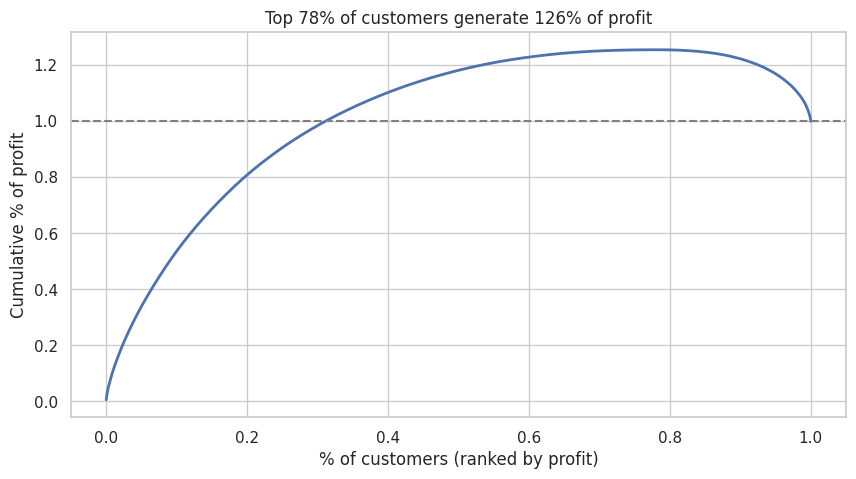

In [25]:
# Whale curve: cumulative profit when customers are ranked from most to least profitable
w = cust["profit"].sort_values(ascending=False).cumsum() / cust["profit"].sum()
x = np.arange(1, len(w) + 1) / len(w)
plt.plot(x, w.values, lw=2)
plt.axhline(1, ls="--", color="gray")
plt.xlabel("% of customers (ranked by profit)"); plt.ylabel("Cumulative % of profit")
plt.title(f"Top {x[w.values.argmax()]:.0%} of customers generate {w.max():.0%} of profit"); plt.show()

**1,058 customer accounts (22%) lose money: –$375K on $2.08M of sales.** They receive a 30% average discount,
compared with 9% for high-profit accounts, and half their lines sit above break-even. They are regular repeat buyers
averaging about 5 orders, so the fix is **repricing, not dropping them**.

### 4.7 Product portfolio

In [26]:
prod = df.groupby("product").agg(sales=("sales", "sum"), profit=("profit", "sum"), avg_discount=("discount", "mean"))
prod["margin"] = prod["profit"] / prod["sales"]
high_sales = prod["sales"] >= prod["sales"].median()
company_margin = total_profit / total_sales

prod["action"] = np.select(
    [high_sales & (prod["profit"] < 0),
     ~high_sales & (prod["profit"] < 0),
     high_sales & (prod["margin"] >= company_margin),
     ~high_sales & (prod["margin"] >= company_margin)],
    ["Reprice (high sales, loss)", "Review / discontinue", "Star - promote", "Niche winner"],
    default="Maintain",
)
portfolio = prod.groupby("action").agg(products=("sales", "size"), sales=("sales", "sum"),
                                       profit=("profit", "sum"), avg_discount=("avg_discount", "mean"))
display(portfolio.sort_values("profit", ascending=False))

prod[prod["action"] == "Reprice (high sales, loss)"].sort_values("profit").head(10)

,products,sales,profit,avg_discount
action,,,,
Star - promote,2857,6178459,"1,708,401.86",0.10
Maintain,1960,2666980,"160,055.60",0.13
Niche winner,2918,532135,"157,758.73",0.09
Review / discontinue,1600,254601,"-84,564.98",0.36
"Reprice (high sales, loss)",1433,3010730,"-474,192.81",0.23


,sales,profit,avg_discount,margin,action
product,,,,,
TEC-MA-10000418 | Cubify CubeX 3D Printer Double Head Print,11100,"-8,879.97",0.53,-0.80,"Reprice (high sales, loss)"
"OFF-AP-10001623 | Hoover Stove, White",11730,"-4,958.16",0.20,-0.42,"Reprice (high sales, loss)"
TEC-MA-10000822 | Lexmark MX611dhe Monochrome Laser Printer,16830,"-4,589.97",0.40,-0.27,"Reprice (high sales, loss)"
"TEC-PH-10002991 | Apple Smart Phone, Full Size",7258,"-4,574.64",0.35,-0.63,"Reprice (high sales, loss)"
"TEC-MOT-10003050 | Motorola Smart Phone, Cordless",10350,"-3,998.68",0.19,-0.39,"Reprice (high sales, loss)"
TEC-MA-10004125 | Cubify CubeX 3D Printer Triple Head Print,8000,"-3,839.99",0.50,-0.48,"Reprice (high sales, loss)"
"FUR-CH-10001582 | Office Star Executive Leather Armchair, Black",6498,"-3,066.78",0.28,-0.47,"Reprice (high sales, loss)"
FUR-TA-10000198 | Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9918,"-2,876.12",0.28,-0.29,"Reprice (high sales, loss)"
"FUR-TA-10002885 | Lesro Computer Table, Fully Assembled",1200,"-2,798.49",0.70,-2.33,"Reprice (high sales, loss)"


**1,432 high-selling products lose $474K on $3.0M of sales.** These products have real demand, so **repricing comes
before delisting**. The "review / discontinue" group is small ($255K of sales) and also heavily discounted (36% on
average).

### 4.8 Shipping cost

,sales,shipping_cost,avg_days,shipping_pct
ship_mode,,,,
Standard Class,7578889,"614,627.65",5.00,0.08
Second Class,2565747,"314,111.79",3.23,0.12
First Class,1831067,"308,102.54",2.18,0.17
Same Day,667202,"115,973.72",0.04,0.17


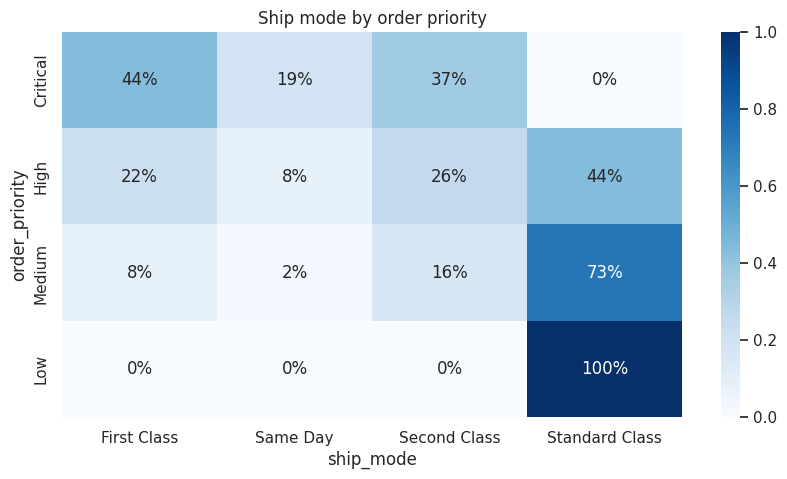

Shipping % of sales by market:
market
APAC     0.11
Africa   0.11
Canada   0.11
EMEA     0.11
EU       0.10
LATAM    0.11
US       0.10
dtype: float64


In [27]:
ship = df.groupby("ship_mode").agg(sales=("sales", "sum"), shipping_cost=("shipping_cost", "sum"), avg_days=("ship_days", "mean"))
ship["shipping_pct"] = ship["shipping_cost"] / ship["sales"]
display(ship.sort_values("shipping_pct"))

mix = pd.crosstab(df["order_priority"], df["ship_mode"], normalize="index")
sns.heatmap(mix.loc[["Critical", "High", "Medium", "Low"]], annot=True, fmt=".0%", cmap="Blues")
plt.title("Ship mode by order priority"); plt.show()

print("Shipping % of sales by market:")
print((df.groupby("market")["shipping_cost"].sum() / df.groupby("market")["sales"].sum()).round(3))

In [28]:
standard_rate = ship.loc["Standard Class", "shipping_pct"]
mismatch = df[df["order_priority"].isin(["Medium", "Low"]) & df["ship_mode"].isin(["First Class", "Same Day"])]
saving = mismatch["shipping_cost"].sum() - mismatch["sales"].sum() * standard_rate
print(f"Medium/Low priority lines shipped express: {len(mismatch):,}  |  potential saving: ${saving:,.0f}")

Medium/Low priority lines shipped express: 3,048  |  potential saving: $25,427


- First Class and Same Day cost about 17% of sales, roughly double Standard Class at 8%.
- About 10% of Medium-priority lines still ship express. Moving them to Standard would save ~$25K, a small but easy win.
- Shipping % is similar across all markets (10–11%), so **shipping does not explain the regional margin gaps**. Discounting does.

### 4.9 What-if: capping discounts

Discounts above a cap are brought down to the cap and priced from list price, with product cost unchanged. Some
customers may walk away when discounts shrink, so each policy is tested at 0%, 25%, 50% and 100% loss of the
affected sales.

,policy,volume_lost,profit,uplift
0,Flat cap 20%,0%,"2,499,720.28",0.70
1,Flat cap 20%,25%,"2,445,176.24",0.67
2,Flat cap 20%,50%,"2,390,632.19",0.63
3,Flat cap 20%,100%,"2,281,544.11",0.55
4,Flat cap 30%,0%,"2,140,976.75",0.46
5,Flat cap 30%,25%,"2,170,978.50",0.48
6,Flat cap 30%,50%,"2,200,980.26",0.50
7,Flat cap 30%,100%,"2,260,983.76",0.54
8,Guardrail: break-even - 5pp,0%,"2,520,505.64",0.72
9,Guardrail: break-even - 5pp,25%,"2,450,894.05",0.67


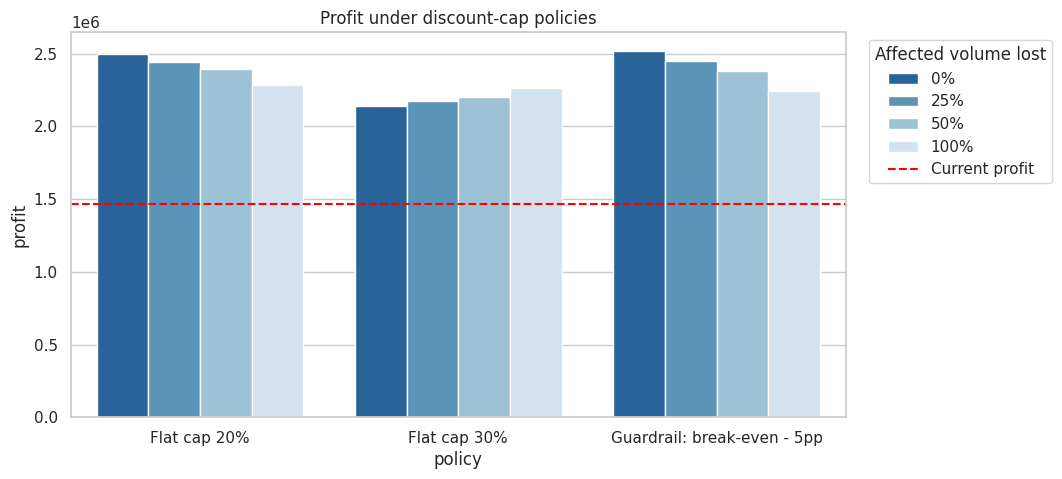

In [29]:
def simulate(cap):
    affected = df["discount"] > cap
    new_sales = df["list_price_sales"] * (1 - np.minimum(df["discount"], cap))
    new_profit = df["profit"] + (new_sales - df["sales"])
    rows = []
    for lost in [0, 0.25, 0.5, 1.0]:
        p = df.loc[~affected, "profit"].sum() + ((1 - lost) * new_profit[affected]).sum()
        rows.append({"volume_lost": f"{lost:.0%}", "profit": p, "uplift": p / total_profit - 1})
    return pd.DataFrame(rows)

policies = {
    "Flat cap 20%": 0.20,
    "Flat cap 30%": 0.30,
    "Guardrail: break-even - 5pp": (df["breakeven_discount"] - 0.05).clip(lower=0),
}
scenarios = pd.concat({name: simulate(cap) for name, cap in policies.items()}).droplevel(1).reset_index(names="policy")
display(scenarios)

sns.barplot(data=scenarios, x="policy", y="profit", hue="volume_lost", palette="Blues_r")
plt.axhline(total_profit, color="red", ls="--", label="Current profit")
plt.title("Profit under discount-cap policies"); plt.legend(title="Affected volume lost", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

- **Even in the worst case, where every affected sale is lost, the 20% cap or the break-even guardrail raises profit by 53–55%.** Those sales lose money today, so losing them still adds profit.
- A flat 30% cap is too loose, because it still allows sales below cost.
- The **break-even guardrail** is recommended because it follows each product's economics. It adds **$0.77M–$1.05M** of profit.

# 5. Conclusions & Recommendations

**Root cause:** Profit leakage comes mainly from **discounts that go beyond each product's break-even point**. That
one issue explains the loss-making sub-category (Tables), the weak regions (Southeast Asia, EMEA), the loss-making
countries and states, and the loss-making customers. Shipping and product mix are secondary.

| # | Recommendation | Evidence | Expected impact |
|---|---|---|---|
| 1 | Set discount limits per sub-category (break-even – 5pp), with approval needed for exceptions | 22% of lines sold below break-even, –$813K | +$0.77M to +$1.05M profit |
| 2 | Audit the flat country price lists, starting with Turkey (60%) and Nigeria (70%) | ~$180K lost in two countries | Removes the biggest country losses |
| 3 | Take Tables out of deep promotions and cap its discount at ~18% | 23% full-price margin vs –8.5% actual | Turns –$64K into profit |
| 4 | Reprice the 1,432 high-sales loss-making products before delisting any | $3.0M sales, –$474K profit | Protects revenue, restores margin |
| 5 | Move loss-making customer accounts onto standard price lists | 30% vs 9% average discount | Recovers part of –$375K |
| 6 | Default Medium- and Low-priority orders to Standard shipping | ~3,000 lines shipped express | ~$25K saving |
| 7 | Track margin and discount depth alongside sales in team targets, especially in Q4 | Margin flat despite +90% sales | Stops growth being bought with discounts |

**Limitations**

- Product cost is inferred from sales minus profit and assumed constant.
- There is no price-sensitivity data, so the scenarios show a range of outcomes rather than a forecast.
- The dataset does not say whether profit already includes shipping cost, so shipping is analysed separately.